# 1. Definición de la Clase de Preprocesamiento
`Preprocesa` sin dependencias de NLTK o spaCy. Se configuran las funciones operativas requeridas para procesar el texto en inglés del dataset de Kaggle:
- Normalización a minúsculas y eliminación de etiquetas HTML recurrentes (`<br />`).
- Remoción de signos de puntuación extendidos y caracteres especiales.
- Tokenización manual basada en secuencias alfanuméricas.
- Filtrado de stopwords en inglés.
- Algoritmo de Stemming basado en sufijos morfológicos.
- Algoritmo de Lematización basado en patrones y lemas irregulares comunes.

In [7]:
import csv
import string


class Preprocesa:

  def __init__(self):
    # Signos de puntuación que se removerán
    self.forbidden = {
        "?", "¿", "¡", "!", "'", '"',
        "‘", "’", "“", "”", "<", ">",
        "(", ")", ".", ",", ":", ";",
        "-", "&", "@", "/", "#", "$",
        "´", "`", "«", "»", "—", "–",
        "…", "•",
    }
    self.all_punctuation = set(string.punctuation).union(self.forbidden)

    # Stopwords en inglés (idioma del dataset)
    self.stop_words = {
        "i",
        "me",
        "my",
        "myself",
        "we",
        "our",
        "ours",
        "ourselves",
        "you",
        "your",
        "yours",
        "yourself",
        "yourselves",
        "he",
        "him",
        "his",
        "himself",
        "she",
        "her",
        "hers",
        "herself",
        "it",
        "its",
        "itself",
        "they",
        "them",
        "their",
        "theirs",
        "themselves",
        "what",
        "which",
        "who",
        "whom",
        "this",
        "that",
        "these",
        "those",
        "am",
        "is",
        "are",
        "was",
        "were",
        "be",
        "been",
        "being",
        "have",
        "has",
        "had",
        "having",
        "do",
        "does",
        "did",
        "doing",
        "a",
        "an",
        "the",
        "and",
        "but",
        "if",
        "or",
        "because",
        "as",
        "until",
        "while",
        "of",
        "at",
        "by",
        "for",
        "with",
        "about",
        "against",
        "between",
        "into",
        "through",
        "during",
        "before",
        "after",
        "above",
        "below",
        "to",
        "from",
        "up",
        "down",
        "in",
        "out",
        "on",
        "off",
        "over",
        "under",
        "again",
        "further",
        "then",
        "once",
        "here",
        "there",
        "when",
        "where",
        "why",
        "how",
        "all",
        "any",
        "both",
        "each",
        "few",
        "more",
        "most",
        "other",
        "some",
        "such",
        "no",
        "nor",
        "not",
        "only",
        "own",
        "same",
        "so",
        "than",
        "too",
        "very",
        "s",
        "t",
        "can",
        "will",
        "just",
        "don",
        "should",
        "now",
    }

    # Diccionario de lemas para formas irregulares comunes en IMDB
    self.lemma_dict = {
        "ran": "run",
        "running": "run",
        "runs": "run",
        "saw": "see",
        "seen": "see",
        "seeing": "see",
        "sees": "see",
        "went": "go",
        "gone": "go",
        "going": "go",
        "goes": "go",
        "was": "be",
        "were": "be",
        "been": "be",
        "being": "be",
        "am": "be",
        "is": "be",
        "are": "be",
        "had": "have",
        "has": "have",
        "having": "have",
        "did": "do",
        "done": "do",
        "does": "do",
        "better": "good",
        "best": "good",
        "worse": "bad",
        "worst": "bad",
        "movies": "movie",
        "films": "film",
        "characters": "character",
        "actors": "actor",
        "scenes": "scene",
        "acting": "act",
        "watched": "watch",
        "watching": "watch",
    }

  # Normaliza la cadena a minúsculas
  def lower_words(self, text):
    return str(text).lower()

  def remove_tags(self, text):
    # Remueve tags como <br />, <br> comunes en el dataset
    while "<" in text and ">" in text:
      start = text.find("<")
      end = text.find(">", start)
      if end == -1:
        break
      text = text[:start] + " " + text[end + 1 :]
    return text

  # Elimina signos de puntuación y reemplaza múltiples espacios por uno sólo
  def remove_punctuation(self, text):
    punctuationfree = "".join(
        [char for char in text if char not in self.all_punctuation]
    )
    return " ".join(punctuationfree.split()).strip()

  # Segmenta la cadena evaluando caracteres alfanuméricos
  def tokenize(self, text):
    tokens = []
    current = []
    for char in text:
      if char.isalnum():
        current.append(char)
      else:
        if current:
          tokens.append("".join(current))
          current = []
    if current:
      tokens.append("".join(current))
    return tokens

  # Filtra las palabras de la lista de tokens verificando si no son stopwords
  def remove_stopwords(self, tokens):
    return [p for p in tokens if p.lower() not in self.stop_words]

  # Stemming: trunca sufijos en inglés preservando la raíz de la palabra
  def stem_word(self, word):
    if len(word) <= 3:
      return word
    suffixes = [
        ("sses", "ss"),
        ("ies", "i"),
        ("ss", "ss"),
        ("s", ""),
        ("eed", "ee"),
        ("ing", ""),
        ("ed", ""),
        ("ly", ""),
        ("tional", "tion"),
        ("izer", "ize"),
        ("ful", ""),
        ("ness", ""),
        ("able", ""),
        ("ible", ""),
    ]
    for suf, rep in suffixes:
      if word.endswith(suf) and len(word) - len(suf) >= 3:
        return word[: -len(suf)] + rep
    return word

  # Aplica la función de stemming a cada token
  def apply_stemming(self, tokens):
    return [self.stem_word(w) for w in tokens]

  # Lematización por reglas y diccionarios léxicos
  def lemmatize_word(self, word):
      # Consulta si existe en el mapeo explícito
    if word in self.lemma_dict:
      return self.lemma_dict[word]
      # Reglas morfólogicas para flexión regular de plurales y tiempos verbales
    if word.endswith("ies") and len(word) > 4:
      return word[:-3] + "y"
    elif word.endswith("es") and len(word) > 3:
      return word[:-2]
    elif word.endswith("s") and not word.endswith("ss") and len(word) > 3:
      return word[:-1]
    elif word.endswith("ed") and len(word) > 4:
      return word[:-2]
    elif word.endswith("ing") and len(word) > 5:
      return word[:-3]
    return word

  # Aplica la lematización a cada token
  def apply_lemmatization(self, tokens):
    return [self.lemmatize_word(w) for w in tokens]

  # Pipeline integrado que ejecuta todo el flujo de limpieza en secuencia
  def pipeline(self, text, method="lemmatize"):
    t_clean = self.remove_tags(self.lower_words(text))
    t_nopunct = self.remove_punctuation(t_clean)
    tokens = self.tokenize(t_nopunct)
    tokens_clean = self.remove_stopwords(tokens)

    if method == "stem":
      res = self.apply_stemming(tokens_clean)
    elif method == "lemmatize":
      res = self.apply_lemmatization(tokens_clean)
    else:
      res = tokens_clean

    return " ".join(res)


print("Clase Preprocesa cargada correctamente.")

Clase Preprocesa cargada correctamente.


# 2. Prueba Unitaria del Preprocesamiento
Comprobamos paso a paso las transformaciones que realiza la clase sobre un extracto de prueba con etiquetas HTML y caracteres especiales.

In [8]:
# Instanciamos la clase de preprocesaminento
prep = Preprocesa()

# Texto de ejemplo
texto_demo = (
    "This movie was one of the BEST I've ever seen! <br /><br /> The actors"
    " were running and acting with real emotion."
)

print("Texto Original:\n", texto_demo)

# 1. Eliminación de etiquetas HTML y signos de puntuación
print(
    "\n1. Sin tags ni signos:",
    prep.remove_punctuation(prep.remove_tags(prep.lower_words(texto_demo))),
)

# 2. Tokenización y remoción de stopwords
print(
    "\n2. Tokenizado sin stopwords:",
    prep.remove_stopwords(
        prep.tokenize(
            prep.remove_punctuation(
                prep.remove_tags(prep.lower_words(texto_demo))
            )
        )
    ),
)

# 3. Flujo completo de lematización
print(
    "\n3. Con Lematización:", prep.pipeline(texto_demo, method="lemmatize")
)

# 4. Flujo completo con Stemming
print("\n4. Con Stemming:", prep.pipeline(texto_demo, method="stem"))

Texto Original:
 This movie was one of the BEST I've ever seen! <br /><br /> The actors were running and acting with real emotion.

1. Sin tags ni signos: this movie was one of the best ive ever seen the actors were running and acting with real emotion

2. Tokenizado sin stopwords: ['movie', 'one', 'best', 'ive', 'ever', 'seen', 'actors', 'running', 'acting', 'real', 'emotion']

3. Con Lematización: movie one good ive ever see actor run act real emotion

4. Con Stemming: movie one best ive ever seen actor runn act real emotion


# 3. Carga del Dataset de Kaggle y Análisis Estadístico
Cargamos el archivo `IMDB Dataset.csv` descargado de Kaggle. Inspeccionamos la cantidad total de registros, la distribución entre clases (`positive` y `negative`) y calculamos estadísticas de longitud de palabras y caracteres.

In [9]:
# Nombre del archivo tal cual se descarga de Kaggle
archivo_kaggle = "IMDB Dataset.csv"

# Listas donde almacenaremos las reseñas y los sentimientos
reviews = []
sentiments = []

# Apertura y lectura del CSV usando la librería nativa csv
with open(archivo_kaggle, mode="r", encoding="utf-8") as f:
  reader = csv.DictReader(f)
  for row in reader:
    reviews.append(row["review"])
    sentiments.append(row["sentiment"])

# Conteo de registros y clases
total_reviews = len(reviews)
pos_count = sentiments.count("positive")
neg_count = sentiments.count("negative")

# Cálculo de longitud de reseñas en palabras y caracteres
word_counts = [len(r.split()) for r in reviews]
char_counts = [len(r) for r in reviews]

# Presentación de las métricas estadísticas descriptivas
print(f"Total de opiniones analizadas: {total_reviews}")
print(
    f"Positivas: {pos_count} ({pos_count/total_reviews*100:.1f}%) | Negativas:"
    f" {neg_count} ({neg_count/total_reviews*100:.1f}%)"
)
print(
    f"Promedio de palabras por opinión: {sum(word_counts)/total_reviews:.2f}"
)
print(f"Longitud mínima: {min(word_counts)} | Longitud máxima: {max(word_counts)}")

Total de opiniones analizadas: 50000
Positivas: 25000 (50.0%) | Negativas: 25000 (50.0%)
Promedio de palabras por opinión: 231.16
Longitud mínima: 4 | Longitud máxima: 2470


# 4. Gráficas Estadísticas y Reporte de Hallazgos
Generamos los gráficos descriptivos del conjunto de datos:
1. Balance exacto de polaridades.
2. Histograma de distribución de palabras por opinión.

A pesar de que el dataset cuenta con un equilibrio de clases (50% positivas y 50% negativas), la distribución de longitud de palabras presenta una asimetría hacia la derecha (cola larga), donde algunas reseñas superan las 1,000 palabras debido a críticas extensas que detallan fallas del guión o aspectos cinematográficos específicos.

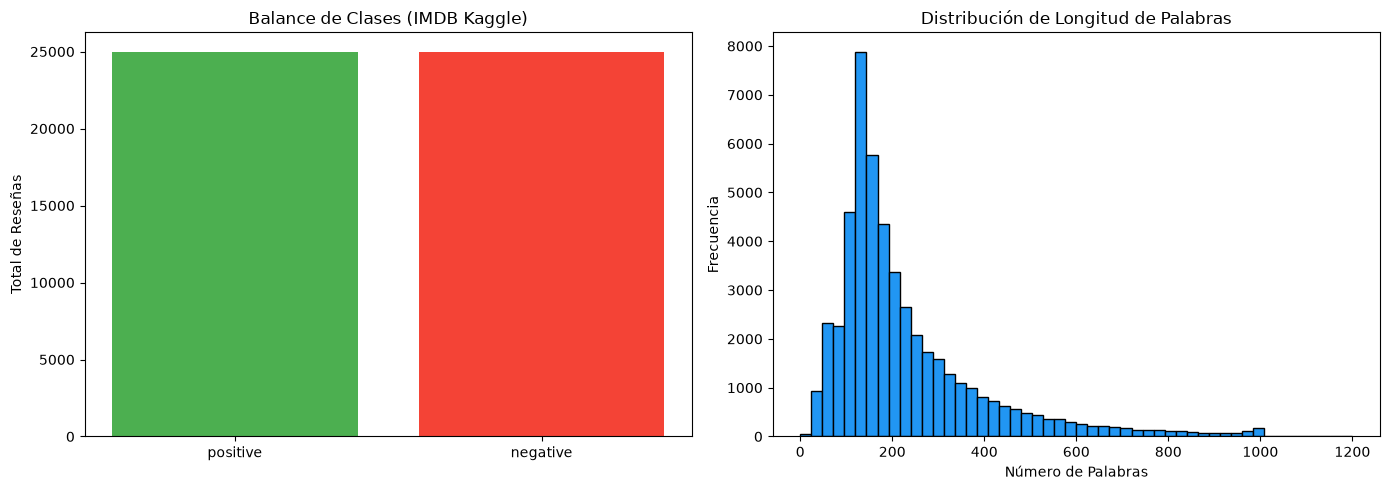

In [10]:
# Importamos matplotlib para generar las visualizaciones estadísticas requeridas
import matplotlib.pyplot as plt

# Creamos un lienzo con 2 subgráficas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Balance de clases (gráfico de barras)
axes[0].bar(
    ["positive", "negative"],
    [pos_count, neg_count],
    color=["#4CAF50", "#F44336"],
)
axes[0].set_title("Balance de Clases (IMDB Kaggle)")
axes[0].set_ylabel("Total de Reseñas")

# Gráfico 2: Histograma de la cantidad de palabras por opinión
axes[1].hist(
    word_counts, bins=50, range=(0, 1200), color="#2196F3", edgecolor="black"
)
axes[1].set_title("Distribución de Longitud de Palabras")
axes[1].set_xlabel("Número de Palabras")
axes[1].set_ylabel("Frecuencia")

# Ajuste automático del espacio entre gráficas
plt.tight_layout()
plt.show()

# 5. Preprocesamiento del Dataset y Frecuencia de Términos
Ejecutamos el pipeline de limpieza sobre las reseñas del archivo de Kaggle para tokenizar, remover signos, eliminar stopwords y lematizar las palabras.

In [11]:
# Importamos Counter de la librería estándar para registrar las frecuencias de las palabras
from collections import Counter

vocab_counter = Counter()

# Definimos el tamaño de muestra para un procesamiento ágil en Colab
n_muestras = 2500
clean_reviews = []

print(f"Limpiando {n_muestras} reseñas de Kaggle...")

# Iteramos sobre la muestra ejecutando nuestro pipeline programado desde cero
for r in reviews[:n_muestras]:
  texto_proc = prep.pipeline(r, method="lemmatize")
  clean_reviews.append(texto_proc)
  # Actualizamos el conteo global de palabras
  vocab_counter.update(texto_proc.split())

print("Preprocesamiento completado.")

# Desplegamos los 15 términos más recurrentes tras el preprocesamiento
print("\nTop 15 términos más frecuentes tras la limpieza:")
for palabra, cant in vocab_counter.most_common(15):
  print(f"{palabra}: {cant}")

Limpiando 2500 reseñas de Kaggle...
Preprocesamiento completado.

Top 15 términos más frecuentes tras la limpieza:
movie: 5063
film: 4643
good: 2599
one: 2474
see: 2370
like: 1869
watch: 1414
character: 1380
go: 1376
get: 1299
bad: 1277
even: 1273
would: 1228
story: 1207
really: 1123


# 6. Generación de Nube de Palabras
Construimos la nube de palabras con base en las frecuencias obtenidas por las funciones programadas desde cero, identificando los términos más significativos del corpus cinematográfico.

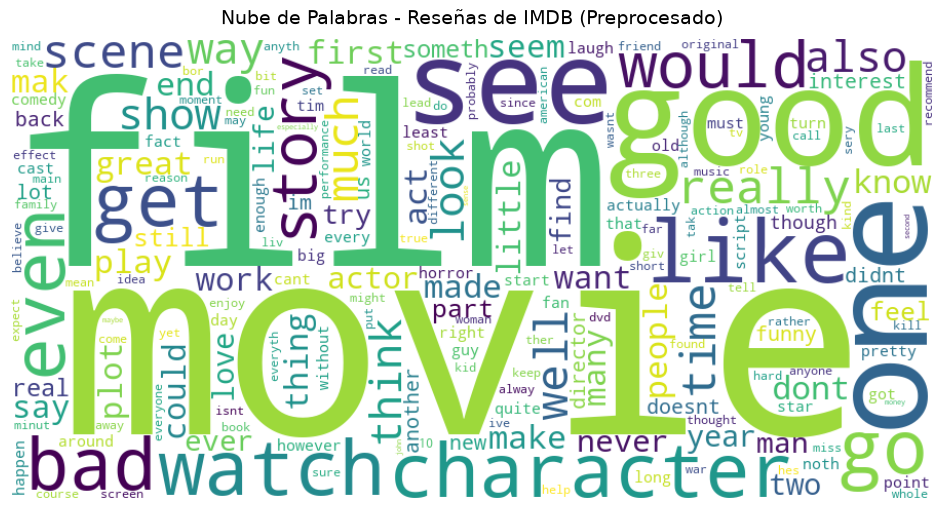

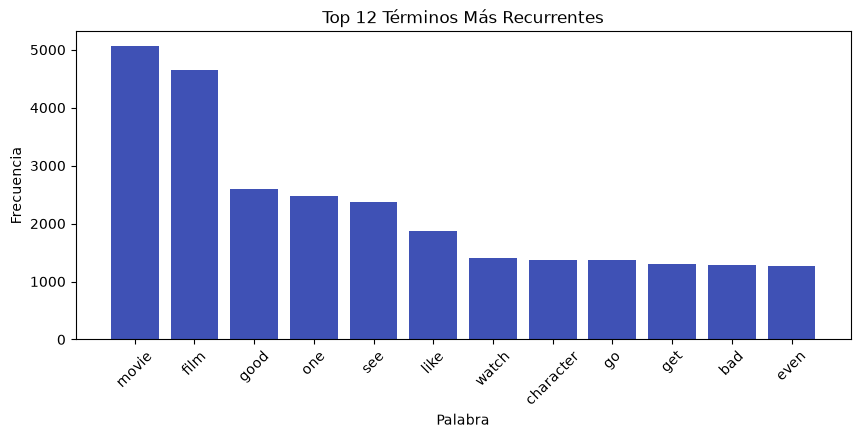

In [12]:
# Importamos la librería WordCloud para graficar la nube de términos
from wordcloud import WordCloud

# Construcción de la nube de palabras a partir del diccionario de frecuencias
wc = WordCloud(
    width=900, height=450, background_color="white", colormap="viridis"
).generate_from_frequencies(vocab_counter)

# Visualización de la nube de palabras
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")  # Ocultamos los ejes numéricos
plt.title(
    "Nube de Palabras - Reseñas de IMDB (Preprocesado)", fontsize=14, pad=10
)
plt.show()

# Gráfico de barras complementario con el Top 12 de términos
top_12 = vocab_counter.most_common(12)
palabras, frecuencias = zip(*top_12)

plt.figure(figsize=(10, 4))
plt.bar(palabras, frecuencias, color="#3F51B5")
plt.title("Top 12 Términos Más Recurrentes")
plt.xlabel("Palabra")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45)
plt.show()

# 7. Exportación del Dataset Limpio a CSV
Exportamos las reseñas preprocesadas junto a sus etiquetas a un archivo `.csv` final denominado `imdb_kaggle_limpio.csv` .

In [13]:
# Definición del nombre del archivo final
archivo_salida = "imdb_kaggle_limpio.csv"

# Escritura del nuevo dataset limpio usando csv.writer
with open(archivo_salida, mode="w", newline="", encoding="utf-8") as f:
  writer = csv.writer(f)
  # Escribimos los encabezados de las columnas
  writer.writerow(["review_limpia", "sentiment"])
  # Escribimos cada reseña preprocesada junto a su polaridad correspondiente
  for r_limpia, sent in zip(clean_reviews, sentiments[:n_muestras]):
    writer.writerow([r_limpia, sent])

print(f"Archivo generado exitosamente: '{archivo_salida}'")

Archivo generado exitosamente: 'imdb_kaggle_limpio.csv'
